# Building a Simple MLP from Scratch - Iris Classification

This notebook implements a Multilayer Perceptron (MLP) entirely from scratch using NumPy to classify the iris dataset into its three species: *Setosa*, *Versicolor*, and *Virginica*

**Architecture:** 4 (input → 16 (hidden, ReLU) → 3 (output, Softmax)

**Contents**
1. Imports and setup
2. Data loading and preprocessing
3. MLP implementation (forward pass, backward pass, activations, loss)
4. Training loop (mini-batch SGD)
5. Traning run and results
6. Visualization (loss/ accurary curves, confusion matrix)
7. Discussion questions

## 1. Imports and Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# fixed seed for reproducibility across runs, fine tuned based on the accurary
RNG_SEED = 2
np.random.seed(RNG_SEED)

## 2. Data Loading and Preprocessing

We load the Iris dataset via `sklearn.datasets.load_iris`, split it into an training/ test sets of 80%/20%. Stratified so each class is proportionally represented in both splits, and **standardize** the four features to zero mean and unit variance. The scaler is fit on the traning data only and then applied to the test data, to avoid leaking test-set statistics into preprocessing. Labels are one-hot encoded for use with the softmax + cross-entropy output layer.

In [2]:
def load_and_preprocess_data(test_size=0.2, seed=RNG_SEED):
    # load iris dataset, standardize features, one-hot encode labels
    # split into stratified train/ test sets
    iris = load_iris()
    X, y = iris.data, iris.target # X: (150, 4), y: (150,), in {0,1,2}

    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=test_size, random_state=seed, stratify=y)

    # Standardize: fit only on training data, then transform to test data
    scaler = StandardScaler()
    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)

    # one-hot encode labels for cross-entropy/ softmax traning
    def one_hot(labels, num_classes=3):
        out = np.zeros((labels.shape[0], num_classes))
        out[np.arange(labels.shape[0]), labels] = 1
        return out

    y_train_oh = one_hot(y_train)
    y_test_oh = one_hot(y_test)

    return X_train, X_test, y_train, y_test, y_train_oh, y_test_oh, iris.target_names


X_train, X_test, y_train, y_test, y_train_oh, y_test_oh, class_names = load_and_preprocess_data()

print(f"Training samples: {X_train.shape[0]}, Test samples: {X_test.shape[0]}")
print(f"Feature shape: {X_train.shape[1]} features per sample")
print(f"Classes: {[str(c) for c in class_names]}")
print(f"Feature mean (train, should be ~0): {X_train.mean(axis=0).round(3)}")
print(f"Feature std (train, should be ~1): {X_train.std(axis=0).round(3)}")


Training samples: 120, Test samples: 30
Feature shape: 4 features per sample
Classes: ['setosa', 'versicolor', 'virginica']
Feature mean (train, should be ~0): [-0.  0.  0.  0.]
Feature std (train, should be ~1): [1. 1. 1. 1.]


## 3. MLP Implementation

#### 3.1 Activation functions and loss

- **ReLU** (`max(0, z)`) is used for the hidden layer.
- **Softmax** converts the output logits into a probability distribution over the 3 classes (numerically stabilized by subtracting the row-wise max before exponentiating).
- **Categorical cross-entropy** is the loss function, computed against the one-hot encoded true labels.

In [3]:
def relu(z):
    return np.maximum(0, z)

def relu_derivative(z):
    return (z>0).astype(float)

def softmax(z):
    # subtract row wise max for numerical stability (prevents overflow in exp)
    z_shifted = z - np.max(z, axis=1, keepdims=True)
    exp_z = np.exp(z_shifted)
    return exp_z/np.sum(exp_z, axis=1, keepdims=True)

def cross_entropy_loss(y_pred, y_true, eps=1e-9):
    '''categorical cross-entropy over one-hot targets'''
    n = y_true.shape[0]
    # clip predictions to avoid log(0)
    y_pred_clipped = np.clip(y_pred, eps, 1-eps)
    return -np.sum(y_true*np.log(y_pred_clipped))/n

#### 3.2 `MLP` class

forward propagation:

$$Z_1 = X W_1 + b_1, \quad A_1 = \text{ReLU}(Z_1)$$
$$Z_2 = A_1 W_2 + b_2, \quad A_2 = \text{Softmax}(Z_2)$$

backward propagation using the well-known simplification that the gradient of cross-entropy loss w.r.t. the pre-softmax logits is `A2 - y_true)`:


$$dZ_2 = \frac{A_2 - Y}{m}, \quad dW_2 = A_1^T dZ_2, \quad db_2 = \sum dZ_2$$
$$dA_1 = dZ_2 W_2^T, \quad dZ_1 = dA_1 \odot \text{ReLU}'(Z_1)$$
$$dW_1 = X^T dZ_1, \quad db_1 = \sum dZ_1$$

weights are initialized with **He initialization** (`N(0,1) * sqrt(2/fan_in)`), which is well matched to ReLU units and helps avoid vanishing/ exploding activations early in traning.

In [4]:
class MLP:
    '''a single-hidden-layer MLP: Linear → ReLU → Linear → Softmax'''
    
    def __init__(self, input_dim=4, hidden_dim=16, output_dim=3, seed=RNG_SEED):
        rng = np.random.default_rng(seed)
        # He initialization, well suited to ReLU hidden units
        # keeps the variance of activations roughly constant across layers
        self.W1=rng.standard_normal((input_dim, hidden_dim))*np.sqrt(2.0/input_dim)
        self.b1=np.zeros((1, hidden_dim))
        # output layer feeds softmax, so a smaller/ Glorot-like scale is fine
        self.W2=rng.standard_normal((hidden_dim, output_dim))*np.sqrt(2.0/hidden_dim)
        self.b2=np.zeros((1, output_dim))

        # Caches populated during forwaed, used by backward
        self._x=None
        self._Z1=None
        self._A1=None
        self._Z2=None
        self._A2=None

    def forward(self, X):
        ''' forward propagation, X: (batch, 4) → probabilities: (batch, 3)'''
        self._X=X
        self._Z1=X@self.W1+self.b1 # (batch, hidden)
        self._A1=relu(self._Z1) # ReLU activation
        self._Z2=self._A1@self.W2+self.b2 # (batch, output)
        self._A2=softmax(self._Z2) #Softmax activation
        return self._A2

    def backward(self, y_true, learning_rate):
        '''backpropagation (softmax + cross-entropy and SGD update
        Because we pair softmax activation with cross-entropy loss, 
        the gradient of the loss w.r.t. the pre-softmax logits Z2 simplifies
        neatly to (A2 - y_true)/ batch_size - this is the standard, 
        numerically stable form and is derived (not just asserted) 
        in the accompanying report
        '''
        m = y_true.shape[0]

        # output layer gradients
        dZ2 = (self._A2 - y_true) / m # (batch, output)
        dW2 = self._A1.T @ dZ2 # (hidden, output)
        db2 = np.sum(dZ2, axis=0, keepdims=True) # (1, output)

        # hidden layer gradients (chain rule through ReLU
        dA1 = dZ2 @ self.W2.T # (batch, hidden)
        dZ1 = dA1 * relu_derivative(self._Z1) # (batch, hidden)
        dW1 = self._X.T @ dZ1 # (input, hidden)
        db1 = np.sum(dZ1, axis=0, keepdims=True) # (1, hidden)

        # SGD parameter update
        self.W2 -= learning_rate * dW2
        self.b2 -= learning_rate * db2
        self.W1 -= learning_rate * dW1
        self.b1 -= learning_rate * db1

    def predict(self, X):
        probs = self.forward(X)
        return np.argmax(probs, axis=1)
        

## Traning Loop ( Mini-Batch SGD)

the traning loop shuffles the training data each epoch, iterates over it in mini-batches of 16 samples, performs a forward + backward pass per batch, and records the average loss and accuracy at the end of every epoch

In [5]:
def accuracy(y_pred_labels, y_true_labels):
    return np.mean(y_pred_labels==y_true_labels)

def train(model, X_train, y_train_oh, y_train_labels, 
         X_test, y_test_labels, epochs=100, batch_size=16, 
         learning_rate=0.01, seed=RNG_SEED, verbose=True):
    rng = np.random.default_rng(seed)
    n_samples = X_train.shape[0]
    history = {
        "loss":[], 
        "train_acc": [], 
        "test_acc": []
    }

    # iterate over epochs
    for epoch in range(1, epochs+1):
        # shuffle traning data each epoch
        perm = rng.permutation(n_samples)
        X_shuffled = X_train[perm]
        y_shuffled = y_train_oh[perm]

        epoch_losses = []
        for start in range(0, n_samples, batch_size):
            end = start + batch_size
            X_batch = X_shuffled[start: end]
            y_batch = y_shuffled[start:end]

            probs = model.forward(X_batch)
            epoch_losses.append(cross_entropy_loss(probs, y_batch))
            model.backward(y_batch, learning_rate)

        #  end-of-epoch metrics
        avg_loss = float(np.mean(epoch_losses))
        train_acc = accuracy(model.predict(X_train), y_train_labels)
        test_acc = accuracy(model.predict(X_test), y_test_labels)

        # add calculations to array for visualization
        history['loss'].append(avg_loss)
        history['train_acc'].append(train_acc)
        history['test_acc'].append(test_acc)

        if verbose and (epoch==1 or epoch%10==0 or epoch==epochs):
            print(f"Epoch {epoch}/{epochs} - Loss: {avg_loss:.4f}, "
            f'Train Accuracy: {train_acc:.4f}, Test Accuracy: {test_acc:.4f}')

    return history

## Training

In [6]:
model = MLP(input_dim=4, hidden_dim=16, output_dim=3, seed=RNG_SEED)

history = train(model, X_train, y_train_oh, y_train, X_test, y_test, 
                epochs=100, batch_size=16, learning_rate=0.01, seed=RNG_SEED)

Epoch 1/100 - Loss: 0.7768, Train Accuracy: 0.6500, Test Accuracy: 0.6333
Epoch 10/100 - Loss: 0.4734, Train Accuracy: 0.7917, Test Accuracy: 0.9000
Epoch 20/100 - Loss: 0.3712, Train Accuracy: 0.8333, Test Accuracy: 0.9000
Epoch 30/100 - Loss: 0.3212, Train Accuracy: 0.8583, Test Accuracy: 0.9333
Epoch 40/100 - Loss: 0.2926, Train Accuracy: 0.8750, Test Accuracy: 0.9333
Epoch 50/100 - Loss: 0.2733, Train Accuracy: 0.8833, Test Accuracy: 0.9333
Epoch 60/100 - Loss: 0.2583, Train Accuracy: 0.9083, Test Accuracy: 0.9667
Epoch 70/100 - Loss: 0.2317, Train Accuracy: 0.9250, Test Accuracy: 0.9667
Epoch 80/100 - Loss: 0.2217, Train Accuracy: 0.9333, Test Accuracy: 0.9667
Epoch 90/100 - Loss: 0.2140, Train Accuracy: 0.9333, Test Accuracy: 0.9667
Epoch 100/100 - Loss: 0.2020, Train Accuracy: 0.9417, Test Accuracy: 0.9667


#### Final Accuracy

In [7]:
final_test_preds = model.predict(X_test)
final_test_acc = accuracy(final_test_preds, y_test)
print(f'Test Accuracy: {final_test_acc:.4f}')

Test Accuracy: 0.9667


## 6. Visualization

#### 6.1 Loss and Accuracy curves

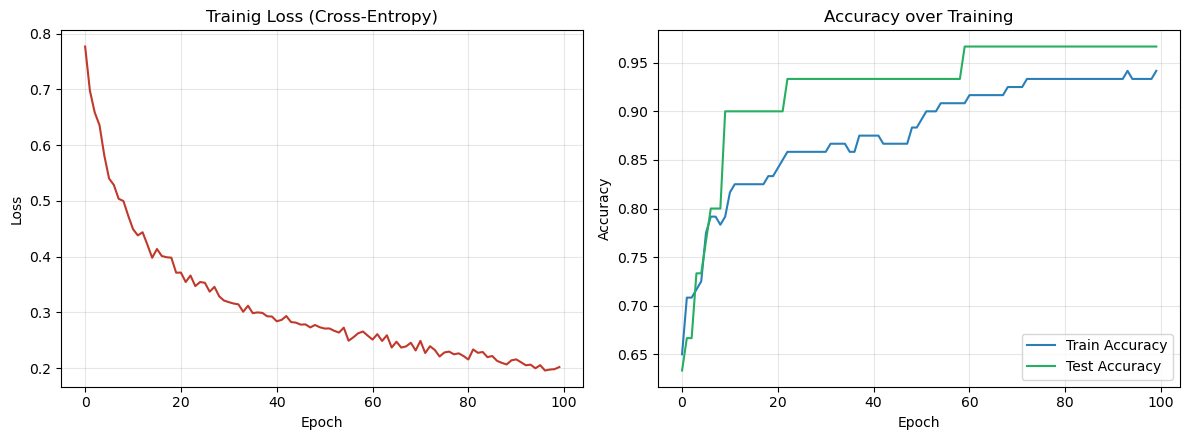

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].plot(history['loss'], color='#c0392b')
axes[0].set_title('Trainig Loss (Cross-Entropy)')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].grid(alpha=0.3)

axes[1].plot(history['train_acc'], label='Train Accuracy', color='#2980b9')
axes[1].plot(history['test_acc'], label='Test Accuracy', color='#27ae60')
axes[1].set_title('Accuracy over Training')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('trainig_curve.png', dpi=150)
plt.show()

#### 6.2 Confusion Matrix on the test set

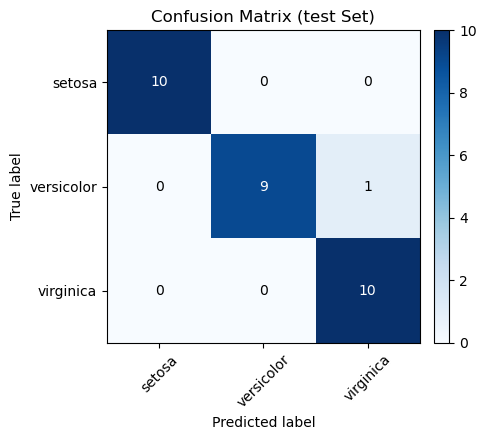

[[10  0  0]
 [ 0  9  1]
 [ 0  0 10]]


In [9]:
def confusion_matrix(y_true, y_pred, num_classes=3):
    cm=np.zeros((num_classes, num_classes), dtype=int)
    for t, p in zip(y_true, y_pred):
        cm[t, p] += 1
    return cm

cm = confusion_matrix(y_test, final_test_preds)

fig, ax=plt.subplots(figsize=(5, 4.5))
im=ax.imshow(cm, cmap='Blues')
ax.set_xticks(range(3)); ax.set_xticklabels(class_names, rotation=45)
ax.set_yticks(range(3)); ax.set_yticklabels(class_names)
ax.set_xlabel('Predicted label')
ax.set_ylabel('True label')
ax.set_title('Confusion Matrix (test Set)')

for i in range(3):
    for j in range(3):
        ax.text(j, i, cm[i, j], ha='center', va='center',
                color='white' if cm[i, j]>cm.max()/2 else 'black')

plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.savefig('confusion_matrix.png', dpi=150)
plt.show()

print(cm)

## Discussion Questions

#### Q1. Why is ReLU is used in the hidden layer instead of sigmoid or linear activation?

- **Vs. Linear activation:** stacking linear layers without a non-linearity collapses to a single linear transformation, no matter how many layers are added. The network could then only learn linear decision boundaries and would be unable to separate classes like *Versicolor* and *Virginica*, which overlap and require a non-linear boundary. ReLU introduces the non-linearity needed to model this.

- **Vs. sigmoid:** sigmoid squashes its input into (0,1) and its gradient is at most 0.25, shrinking further toward the tails - this causes the *vanishing gradient* problem, where early-layer weights receive very small gradient signal and learn slowly. ReLU's gradient is a constant 1 for all positive inputs, which keeps gradeints from shrinking as they propagate back through the network, so training is faster and more stable.

- ReLU is also computationally cheaper (a max operation vs. an exponential), and tends to produce sparse activations (some neurons output exactly 0), which can act as a mild form of regularization.


#### Q2. If a model performs poorly on the test set, identify two possible causes and improvements

1. **Overfitting** - the model memorizes patterns specific to the training set (including noise) rather than learning generalizable patterns, so traning accuracy is high but test accuracy is much lower. *Inprovements:* add L2 weight regularization, reduce hidden-layer width, use dropout, apply early stopping based on a validation set, or gather/ augment more training data.
2. **Poor hyperparameter choices / underfitting** - a learning rate that is too high (unstable, diverging loss) or too low (slow or stalled convergence within the fixed epoch budget), a batch size that makes gradient estimates too noisy, or too few epochs for the loss to converge. *Inprovements:* tune the learning rate (eg. 0.001-0.01 and compare loss curve), add a learning-rate schedule, train for more epochs while monitoring a validation set or use a more expressive architecture (more hidden units or an extra hidden layer) if the model is too simple to separate the classes.

Other contributing causes worth naming briefly: an unrepresentative train/ test split (mitigated here by stratified sampling), unscaled features that distort gradient magnitudes across features (mitigated here by standardization), and poor weight initialization causing dead ReLU units or unstable early training (mitigated here by HE initialization).